# Modul 9: Attention dan Arsitektur Transformer (Capstone)

**Nama:** Ahmad Farhan Ghani  
**NIM:** 123450121  
**Kelas:** RA  
**Tanggal:** 2026-11-18  

Simpan berkas ini sebagai `M09_NIM.ipynb` sebelum mulai mengerjakan.

## Petunjuk

Notebook ini memiliki tiga jenis bagian. Tanda di akhir judul menunjukkan jenisnya.

| Tanda | Bagian | Yang Anda lakukan |
|:---|:---|:---|
| **Terbimbing** | A–G | Jawaban lengkap Prosedur Praktikum Terbimbing sudah tersedia, termasuk contoh jawaban pre-lab. Jalankan, baca kodenya, lalu cocokkan keluarannya dengan tab **Materi** modul. |
| **Latihan Mandiri di Lab** | Latihan | Dikerjakan sendiri di laboratorium setelah bagian terbimbing. |
| **Tugas Individu** | H–I | Dikerjakan di luar sesi dan dikumpulkan lewat Tugas. |

1. Isi identitas di atas dan `NIM` pada sel pertama. Seed individual adalah empat digit terakhir NIM, sama dengan Modul 8. Hanya itu isian pada bagian terbimbing.
2. Pastikan `data/raw/ag_news/train.csv` tersedia lewat tombol **Siapkan dataset di laptop** di halaman modul. Tekan **Restart**, lalu **Run all**. Dengan `MODE_TUGAS = False` (quick mode: 2.400 latih, 600 validasi, 2 epoch, satu seed), seluruh sel terbimbing berjalan di kernel Deep Learning (PyTorch CPU) dan berhenti di sel Latihan pertama yang masih berisi `TODO`.
3. Keluaran yang tidak bergantung pada NIM, misalnya anggaran parameter di bagian E, harus sama persis dengan naskah. Angka attention acak, probe, dan hasil training bergantung pada seed NIM Anda; waktu bergantung pada mesin.
4. Ketiga probe di bagian D dijalankan pada model **belum terlatih**. Norma gradien dicatat **sebelum** clipping dan checkpoint dipilih dari validation loss.
5. Pada bagian Latihan dan Tugas, ganti seluruh penanda `TODO`. Untuk Tugas, ubah `MODE_TUGAS = True` (6.000/1.500, 4 epoch, tiga seed, dua belas run); bagian terbimbing ikut berjalan dengan protokol itu. Quick mode tidak boleh dipakai sebagai hasil pengumpulan, dan test set tidak dipakai selama praktikum.
6. Sebelum mengumpulkan, jalankan **Restart** lalu **Run all** sampai seluruh sel selesai tanpa galat. Pertahankan semua hasil eksperimen, termasuk ablasi yang tidak sesuai hipotesis.

In [1]:
import copy
import math
import platform
import random
import re
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, TensorDataset

# Kernel Workbench menangkap figure di akhir setiap sel; plt.show() dipertahankan
# agar notebook tetap berjalan di Jupyter biasa, tanpa peringatan backend Agg.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

NIM = '123450121'  # Ganti dengan NIM lengkap Anda, misalnya '120140167'.
assert NIM.isdigit() and len(NIM) >= 4, 'Isi NIM dengan angka sebelum melanjutkan.'
BASE_SEED = int(NIM[-4:])  # seed individual, sama dengan Modul 8
MODE_TUGAS = True  # WAJIB True pada hasil pengumpulan
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
TRAIN_N, VAL_N, EPOCHS = ((6_000, 1_500, 4) if MODE_TUGAS
                          else (2_400, 600, 2))
SEEDS = ([BASE_SEED, BASE_SEED + 1, BASE_SEED + 2]
         if MODE_TUGAS else [BASE_SEED])

def seed_everything(seed: int) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def sync_device() -> None:
    if torch.cuda.is_available():
        torch.cuda.synchronize()

seed_everything(BASE_SEED)
pd.set_option('display.precision', 4)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
print({'python': platform.python_version(), 'torch': torch.__version__,
       'device': str(DEVICE), 'mode_tugas': MODE_TUGAS,
       'train': TRAIN_N, 'validation': VAL_N, 'epochs': EPOCHS,
       'seeds': SEEDS})

{'python': '3.12.3', 'torch': '2.15.0+cu132', 'device': 'cpu', 'mode_tugas': True, 'train': 6000, 'validation': 1500, 'epochs': 4, 'seeds': [121, 122, 123]}


## A. Pre-lab dan attention dari nol · Terbimbing

### Pre-lab

Contoh jawaban. Bandingkan dengan jawaban Anda sendiri sebelum sesi.

1. **Mengapa skor dot-product dibagi $\sqrt{d_k}$?** Bila komponen $q$ dan $k$ saling bebas dengan rerata nol dan ragam satu, $q\cdot k=\sum_{i=1}^{d_k}q_ik_i$ memiliki ragam $d_k$. Tanpa pembagian, skor makin lebar saat $d_k$ besar sehingga softmax jenuh (hampir one-hot) dan gradiennya mendekati nol. Membagi dengan $\sqrt{d_k}$ mengembalikan ragam skor ke sekitar 1.
2. **Mengapa tanpa penyandian posisi model tidak dapat membedakan "anjing menggigit orang" dari "orang menggigit anjing"?** Self-attention menghitung bobot dari isi token saja dan menjumlahkannya; operasi ini *permutation-equivariant*, dan setelah pooling rata-rata menjadi invarian terhadap permutasi. Dua kalimat dengan multiset token yang sama menghasilkan representasi identik; posisi hanya masuk lewat penyandian yang ditambahkan ke embedding.
3. **Di dua tempat mana mask harus diterapkan?** (a) Pada skor attention sebelum softmax (`masked_fill` / `src_key_padding_mask`) agar tidak ada query yang memberi bobot ke `<pad>`; (b) pada pooling akhir, dengan hanya merata-ratakan token asli dan membagi dengan panjang sebenarnya, bukan `MAKS`.
4. **Mengapa menambah head tidak menambah parameter bila $d_{\text{model}}$ tetap?** Tuliskan ukuran $W_Q, W_K, W_V, W_O$ sebagai fungsi $d_{\text{model}}$ dan $h$, lalu periksa apakah $h$ muncul pada jumlah bobotnya. Pembuktian dengan angka untuk $h\in\{1,2,4,10\}$ dikerjakan pada Latihan Mandiri.

In [2]:
def attention(Q, K, V, mask=None, skala=True):
    """Langkah 1: scaled dot-product attention; mask True = diabaikan."""
    d_k = Q.size(-1)
    skor = Q @ K.transpose(-2, -1)
    if skala:
        skor = skor / math.sqrt(d_k)
    if mask is not None:
        skor = skor.masked_fill(mask, float('-inf'))     # SEBELUM softmax
    bobot = torch.softmax(skor, dim=-1)
    return bobot @ V, bobot

seed_everything(BASE_SEED)
n, d_k = 5, 8
Q, K, V = (torch.randn(1, n, d_k) for _ in range(3))
keluaran, bobot = attention(Q, K, V)
acuan = F.scaled_dot_product_attention(Q, K, V)
selisih = (keluaran - acuan).abs().max().item()
print('bentuk bobot:', tuple(bobot.shape), '| selisih PyTorch:', f'{selisih:.2e}')
assert torch.allclose(bobot.sum(-1), torch.ones(1, n), atol=1e-6), \
    'setiap baris bobot harus berjumlah satu'
assert selisih < 1e-5, 'implementasi belum cocok dengan PyTorch'

bentuk bobot: (1, 5, 5) | selisih PyTorch: 1.19e-07


In [3]:
# Langkah 2: entropi rerata bobot attention.
def entropi_rerata(d_k, skala, n=64, seed=BASE_SEED):
    seed_everything(seed)
    Q, K, V_ = (torch.randn(1, n, d_k) for _ in range(3))
    _, w = attention(Q, K, V_, skala=skala)
    h = -(w * torch.log(w.clamp_min(1e-12))).sum(-1)
    return h.mean().item()

tabel_entropi = pd.DataFrame([
    {'d_k': d, 'skala': s, 'entropi': entropi_rerata(d, s), 'entropi_maks': math.log(64)}
    for d in (8, 256) for s in (True, False)])
print(tabel_entropi.to_string(index=False))

 d_k  skala  entropi  entropi_maks
   8   True   3.5963        4.1589
   8  False   1.8863        4.1589
 256   True   3.6906        4.1589
 256  False   0.2742        4.1589


**Interpretasi $\sqrt{d_k}$.** Angka dihitung dari tabel di atas.

In [4]:
e = tabel_entropi.set_index(['d_k', 'skala'])['entropi']
display(Markdown(f"""
Entropi maksimum $\\log 64\\approx{math.log(64):.2f}$. Dengan skala, entropi rerata {e[(8, True)]:.2f} ($d_k=8$) dan {e[(256, True)]:.2f} ($d_k=256$) — hampir sama dan dekat maksimum. Tanpa skala: {e[(8, False)]:.2f} dan {e[(256, False)]:.2f}. Varians skor $q\\cdot k$ tumbuh sebanding $d_k$, jadi tanpa pembagian $\\sqrt{{d_k}}$ skor pada $d_k=256$ jauh lebih lebar dan softmax nyaris *one-hot* (entropi rendah). Softmax yang jenuh memberi gradien mendekati nol untuk hampir semua posisi, sehingga pelatihan melambat atau macet; pembagian $\\sqrt{{d_k}}$ menjaga varians skor ≈1 di dimensi berapa pun.
"""))


Entropi maksimum $\log 64\approx4.16$. Dengan skala, entropi rerata 3.60 ($d_k=8$) dan 3.69 ($d_k=256$) — hampir sama dan dekat maksimum. Tanpa skala: 1.89 dan 0.27. Varians skor $q\cdot k$ tumbuh sebanding $d_k$, jadi tanpa pembagian $\sqrt{d_k}$ skor pada $d_k=256$ jauh lebih lebar dan softmax nyaris *one-hot* (entropi rendah). Softmax yang jenuh memberi gradien mendekati nol untuk hampir semua posisi, sehingga pelatihan melambat atau macet; pembagian $\sqrt{d_k}$ menjaga varians skor ≈1 di dimensi berapa pun.


## B. Pipeline AG News (disediakan) · Terbimbing

Sel berikut menyalin pipeline Modul 7--8 apa adanya agar waktu praktikum
difokuskan pada attention. Jangan mengubah split, sumber vocabulary, atau
indeks token khusus.

In [5]:
ROOT = Path('../../data/raw/ag_news')
if not ROOT.exists():
    ROOT = Path('data/raw/ag_news')
train_file = ROOT / 'train.csv'
if not train_file.exists():
    raise FileNotFoundError(
        f'{train_file} tidak ditemukan. Ikuti petunjuk data/README.md')

kolom = ['label', 'judul', 'ringkasan']
data = pd.read_csv(train_file, names=kolom, header=None)
if not str(data.iloc[0]['label']).strip().isdigit():
    data = data.iloc[1:].reset_index(drop=True)
data['teks'] = data['judul'].astype(str) + ' ' + data['ringkasan'].astype(str)
data['y'] = data['label'].astype(int) - 1

idx_train, idx_val = train_test_split(
    np.arange(len(data)), train_size=TRAIN_N, test_size=VAL_N,
    stratify=data['y'].to_numpy(), random_state=BASE_SEED)
teks_train = data['teks'].to_numpy()[idx_train]
teks_val = data['teks'].to_numpy()[idx_val]
y_train = data['y'].to_numpy()[idx_train]
y_val = data['y'].to_numpy()[idx_val]

POLA = re.compile(r"[a-z0-9']+")
def tokenisasi(teks):
    return POLA.findall(str(teks).lower())

cacah = Counter(t for s in teks_train for t in tokenisasi(s))
kosakata = ['<pad>', '<unk>'] + [w for w, n_ in cacah.most_common() if n_ >= 2]
stoi = {w: i for i, w in enumerate(kosakata)}
itos = {i: w for w, i in stoi.items()}
V = len(kosakata)

MAKS = 60
def ke_indeks(daftar_teks, maks=MAKS):
    X = torch.zeros(len(daftar_teks), maks, dtype=torch.long)
    L = torch.zeros(len(daftar_teks), dtype=torch.long)
    for i, teks in enumerate(daftar_teks):
        token = [stoi.get(t, 1) for t in tokenisasi(teks)][:maks] or [1]
        X[i, :len(token)] = torch.tensor(token); L[i] = len(token)
    return X, L

X_train, L_train = ke_indeks(teks_train)
X_val, L_val = ke_indeks(teks_val)
ds_train = TensorDataset(X_train, L_train, torch.tensor(y_train))
ds_val = TensorDataset(X_val, L_val, torch.tensor(y_val))
print({'train': len(ds_train), 'validation': len(ds_val), 'vocabulary': V})
assert kosakata[:2] == ['<pad>', '<unk>']
assert L_train.min() >= 1 and L_train.max() <= MAKS

{'train': 6000, 'validation': 1500, 'vocabulary': 11862}


## C. Penyandian posisi dan model · Terbimbing

In [6]:
def penyandian_posisi(maks_len, d):
    """Langkah 3: PE sinusoidal (maks_len, d), tanpa parameter terlatih."""
    pos = torch.arange(maks_len).unsqueeze(1).float()
    i = torch.arange(0, d, 2).float()
    pembagi = torch.exp(-math.log(10000.0) * i / d)      # 1 / 10000^(2i/d)
    pe = torch.zeros(maks_len, d)
    pe[:, 0::2] = torch.sin(pos * pembagi)
    pe[:, 1::2] = torch.cos(pos * pembagi)
    return pe

PE = penyandian_posisi(256, 100)
assert PE.shape == (256, 100)
assert not torch.allclose(PE[3], PE[7]), 'posisi berbeda harus tersandi berbeda'
assert PE.abs().max() <= 1.0 + 1e-6
print('PE siap:', tuple(PE.shape))

PE siap: (256, 100)


In [7]:
D_MODEL, N_HEAD, FF, KELAS = 100, 4, 175, 4

class TransformerClassifier(nn.Module):
    def __init__(self, pakai_posisi=True, pakai_mask=True,
                 d=D_MODEL, nhead=N_HEAD, ff=FF, dropout=0.1):
        super().__init__()
        self.pakai_posisi, self.pakai_mask, self.d = pakai_posisi, pakai_mask, d
        self.embedding = nn.Embedding(V, d, padding_idx=0)
        self.layer = nn.TransformerEncoderLayer(
            d_model=d, nhead=nhead, dim_feedforward=ff,
            dropout=dropout, batch_first=True)
        self.head = nn.Linear(d, KELAS)
        self.register_buffer('pe', penyandian_posisi(256, d), persistent=False)

    def masukan(self, X):
        h = self.embedding(X)
        if self.pakai_posisi:
            h = h + self.pe[:X.size(1)].unsqueeze(0)
        return h

    def forward(self, X, panjang):
        h = self.masukan(X)
        pad = (X == 0)                                    # True = diabaikan
        h = self.layer(h, src_key_padding_mask=pad if self.pakai_mask else None)
        if self.pakai_mask:
            m = (~pad).unsqueeze(-1).to(h.dtype)
            wakil = (h * m).sum(1) / panjang.to(h.dtype).unsqueeze(1).clamp_min(1.0)
        else:
            wakil = h.mean(1)                             # ikut merata-ratakan bantalan
        return self.head(wakil)

class LSTMClassifier(nn.Module):
    """Pembanding rekuren Modul 8; disediakan agar protokol identik."""
    def __init__(self, hidden=96, d=D_MODEL):
        super().__init__()
        self.embedding = nn.Embedding(V, d, padding_idx=0)
        self.encoder = nn.LSTM(d, hidden, batch_first=True)
        self.head = nn.Linear(hidden, KELAS)

    def forward(self, X, panjang):
        emb = self.embedding(X)
        packed = pack_padded_sequence(emb, panjang.cpu(), batch_first=True,
                                      enforce_sorted=False)
        _, (h_n, _) = self.encoder(packed)
        return self.head(h_n[-1])

seed_everything(BASE_SEED)
m = TransformerClassifier().eval()
with torch.no_grad():
    logits = m(X_val[:4], L_val[:4])
assert logits.shape == (4, KELAS), 'logit harus berbentuk (B, 4)'
assert 'pe' in dict(m.named_buffers()), \
    'PE harus didaftarkan sebagai buffer, bukan parameter yang dilatih'
print('logit:', tuple(logits.shape))

logit: (4, 4)


## D. Tiga probe berupa angka · Terbimbing

Seluruh probe dijalankan pada model **belum terlatih**: yang diuji arsitektur,
bukan hasil belajar.

In [8]:
# Langkah 7 (probe permutasi): acak token ASLI contoh terpanjang.
i = int(L_val.argmax())
x1, l1 = X_val[i:i + 1], L_val[i:i + 1]
n_asli = int(l1[0])

g = torch.Generator().manual_seed(BASE_SEED)
urutan = torch.randperm(n_asli, generator=g)
x2 = x1.clone()
x2[0, :n_asli] = x1[0, urutan]          # bantalan tetap di kanan

baris = []
for posisi in (False, True):
    seed_everything(BASE_SEED)
    mdl = TransformerClassifier(pakai_posisi=posisi).eval()
    with torch.no_grad():
        d = (mdl(x1, l1) - mdl(x2, l1)).abs().max().item()
    baris.append({'penyandian_posisi': posisi, 'selisih_logit_permutasi': d})
probe1 = pd.DataFrame(baris)

print(probe1.to_string(index=False))
assert probe1.loc[0, 'selisih_logit_permutasi'] < 1e-4, \
    'tanpa penyandian posisi seharusnya invarian terhadap permutasi'
assert probe1.loc[1, 'selisih_logit_permutasi'] > 1e-3, \
    'dengan penyandian posisi seharusnya berubah'

 penyandian_posisi  selisih_logit_permutasi
             False               2.9802e-08
              True               4.5938e-03


In [9]:
# Langkah 8 (probe bantalan): 8 contoh + 20 kolom <pad>.
xb, lb = X_val[:8], L_val[:8]
xb_panjang = torch.cat([xb, torch.zeros(8, 20, dtype=torch.long)], dim=1)

baris = []
for pakai_mask in (False, True):
    seed_everything(BASE_SEED)
    mdl = TransformerClassifier(pakai_mask=pakai_mask).eval()
    with torch.no_grad():
        d = (mdl(xb, lb) - mdl(xb_panjang, lb)).abs().max().item()
    baris.append({'mask': pakai_mask, 'selisih_logit_bantalan': d})
probe2 = pd.DataFrame(baris)

print(probe2.to_string(index=False))
assert probe2.loc[0, 'selisih_logit_bantalan'] > 1e-3, 'tanpa mask harus berubah'
assert probe2.loc[1, 'selisih_logit_bantalan'] < 1e-4, 'dengan mask harus stabil'

 mask  selisih_logit_bantalan
False                  0.1684
 True                  0.0000


In [10]:
# Langkah 9 (probe bobot): massa bobot ke kolom bantalan, dengan/tanpa mask.
# Contoh terpanjang terpotong tepat MAKS token sehingga tidak berbantalan;
# seperti probe 2, tambahkan 20 kolom <pad> agar ada bantalan yang diuji.
x3 = torch.cat([x1, torch.zeros(1, 20, dtype=torch.long)], dim=1)
seed_everything(BASE_SEED)
mdl = TransformerClassifier().eval()
with torch.no_grad():
    h = mdl.masukan(x3)
    pad = (x3 == 0)
    _, w_mask = mdl.layer.self_attn(h, h, h, key_padding_mask=pad, need_weights=True)
    _, w_polos = mdl.layer.self_attn(h, h, h, need_weights=True)

massa_mask = w_mask[0, :n_asli, n_asli:].sum().item()
massa_polos = w_polos[0, :n_asli, n_asli:].sum().item()

print(f'{n_asli} token asli + {x3.size(1) - n_asli} kolom bantalan')
print(f'massa ke bantalan dengan mask: {massa_mask:.2e} | tanpa mask: {massa_polos:.4f}')
assert massa_mask < 1e-6, 'mask aktif harus membuat massa bobot bantalan nol'

60 token asli + 20 kolom bantalan
massa ke bantalan dengan mask: 0.00e+00 | tanpa mask: 12.0344


**Bukti angka.** Angka di bawah dihitung dari ketiga probe.

In [11]:
display(Markdown(f"""
- Selisih logit akibat permutasi, tanpa / dengan penyandian posisi: **{probe1.loc[0, 'selisih_logit_permutasi']:.1e}** / **{probe1.loc[1, 'selisih_logit_permutasi']:.4f}**.
- Selisih logit akibat penambahan bantalan, tanpa / dengan mask: **{probe2.loc[0, 'selisih_logit_bantalan']:.4f}** / **{probe2.loc[1, 'selisih_logit_bantalan']:.1e}**.
- Massa bobot pada posisi bantalan, tanpa / dengan mask: **{massa_polos:.4f}** / **{massa_mask:.1e}** (dijumlahkan atas {n_asli} query; rata-rata {massa_polos / n_asli:.3f} per query dari {x3.size(1) - n_asli} kolom bantalan).
"""))


- Selisih logit akibat permutasi, tanpa / dengan penyandian posisi: **3.0e-08** / **0.0046**.
- Selisih logit akibat penambahan bantalan, tanpa / dengan mask: **0.1684** / **0.0e+00**.
- Massa bobot pada posisi bantalan, tanpa / dengan mask: **12.0344** / **0.0e+00** (dijumlahkan atas 60 query; rata-rata 0.201 per query dari 20 kolom bantalan).


## E. Anggaran parameter · Terbimbing

In [12]:
def parameter_layer(d, ff):
    """Langkah 10: multi-head 4d^2 + 4d; feed-forward 2df + f + d; dua LayerNorm 4d."""
    return (4 * d * d + 4 * d) + (2 * d * ff + ff + d) + 4 * d

def parameter_lstm(hidden, d=D_MODEL):
    return 4 * hidden * (d + hidden + 2)

acuan = parameter_lstm(96) + 96 * KELAS + KELAS
head_trf = D_MODEL * KELAS + KELAS

def ff_terdekat(target, d=D_MODEL, batas=1024):
    """Langkah 11: integer f dengan selisih anggaran terkecil."""
    return min(range(1, batas + 1),
               key=lambda f: abs(parameter_layer(d, f) + head_trf - target))

FF_CARI = ff_terdekat(acuan)
enc_teori = parameter_layer(D_MODEL, FF_CARI)
seed_everything(BASE_SEED)
enc_nyata = sum(p.numel() for p in
                nn.TransformerEncoderLayer(d_model=D_MODEL, nhead=N_HEAD,
                                           dim_feedforward=FF_CARI,
                                           batch_first=True).parameters())
total_trf = enc_teori + head_trf
print(f'acuan LSTM H=96: {acuan:,} | f terdekat: {FF_CARI} '
      f'| Transformer: {total_trf:,} '
      f'| selisih {100 * (total_trf - acuan) / acuan:+.2f}%')
assert enc_teori == enc_nyata, 'rumus belum cocok dengan PyTorch'
assert FF_CARI == FF, 'f yang ditemukan harus sama dengan FF yang dipakai'
assert abs(total_trf - acuan) / acuan <= 0.01, 'selisih anggaran melebihi 1%'

acuan LSTM H=96: 76,420 | f terdekat: 175 | Transformer: 76,479 | selisih +0.08%


## F. Dua run quick mode · Terbimbing

Satu fungsi pelatihan, `jalankan`, dipakai untuk seluruh konfigurasi: Adam $10^{-3}$, batch 64, gradient clipping 1,0, norma gradien dicatat sebelum clipping, dan checkpoint dengan validation loss terendah dimuat kembali di akhir. Bagian ini melatih Transformer penuh dan LSTM $H=96$ pada seed individual dengan protokol dari sel setup (quick mode secara bawaan). Dua belas run multi-seed memakai fungsi yang sama pada bagian H.

In [13]:
BATCH = 64

def buat_loader(ds, shuffle, seed, batch=BATCH):
    generator = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(ds, batch_size=batch, shuffle=shuffle, generator=generator)

@torch.no_grad()
def evaluasi(model, ds):
    """Loss rata-rata dan akurasi pada seluruh dataset, dalam mode evaluasi."""
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction='sum')
    total_loss, benar = 0.0, 0
    for xb, lb, yb in buat_loader(ds, False, BASE_SEED, 256):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb, lb)
        total_loss += criterion(logits, yb).item()
        benar += (logits.argmax(1) == yb).sum().item()
    return total_loss / len(ds), benar / len(ds)

def bangun(nama, seed):
    seed_everything(seed)
    if nama == 'lstm-h96':
        return LSTMClassifier(96)
    return TransformerClassifier(pakai_posisi=nama != 'trf-tanpa-posisi',
                                 pakai_mask=nama != 'trf-tanpa-mask')

def jalankan(nama, seed):
    """Satu fungsi pelatihan untuk seluruh konfigurasi; kembalikan (model, history, catatan)."""
    model = bangun(nama, seed).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()
    loader = buat_loader(ds_train, True, seed)
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'grad_norm': []}
    best_loss, best_state, best_epoch, n_update = float('inf'), None, 0, 0
    sync_device(); mulai = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        model.train(); jumlah = 0.0
        for xb, lb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb, lb), yb)
            loss.backward()
            norm = torch.sqrt(sum((p.grad.detach() ** 2).sum()
                                  for p in model.parameters()
                                  if p.grad is not None)).item()
            history['grad_norm'].append(norm)            # SEBELUM clipping
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step(); n_update += 1
            jumlah += loss.item() * len(yb)
        val_loss, val_acc = evaluasi(model, ds_val)
        history['train_loss'].append(jumlah / len(ds_train))
        history['val_loss'].append(val_loss); history['val_acc'].append(val_acc)
        print(f'  epoch {epoch}/{EPOCHS}  train_loss {history["train_loss"][-1]:.4f}  '
              f'val_loss {val_loss:.4f}  val_acc {val_acc:.4f}', flush=True)
        if val_loss < best_loss:                         # checkpoint terbaik (validation loss)
            best_loss, best_state, best_epoch = val_loss, copy.deepcopy(model.state_dict()), epoch

    sync_device(); durasi = time.perf_counter() - mulai
    model.load_state_dict(best_state)
    train_loss, _ = evaluasi(model, ds_train)
    val_loss, val_acc = evaluasi(model, ds_val)
    enc = model.layer if hasattr(model, 'layer') else model.encoder
    enc_n = sum(p.numel() for p in enc.parameters())
    total_n = sum(p.numel() for p in model.parameters())
    catatan = {
        'run_id': f'{nama}-s{seed}', 'module': 'M09', 'NIM': NIM, 'seed': seed,
        'arsitektur': 'lstm' if nama == 'lstm-h96' else 'transformer',
        'posisi': nama not in ('trf-tanpa-posisi', 'lstm-h96'),
        'mask': nama != 'trf-tanpa-mask',
        'd_model': D_MODEL, 'n_head': N_HEAD if nama != 'lstm-h96' else 0,
        'dim_feedforward': FF if nama != 'lstm-h96' else 0,
        'max_length': MAKS, 'train_size': len(ds_train),
        'val_size': len(ds_val), 'epochs': EPOCHS, 'n_updates': n_update,
        'best_epoch': best_epoch,
        'encoder_parameters': enc_n,
        'encoder_head_parameters': enc_n + sum(p.numel() for p in model.head.parameters()),
        'total_parameters': total_n,
        'model_mib_fp32': 4 * total_n / 1024 ** 2,
        'train_loss': train_loss, 'val_loss': val_loss, 'val_accuracy': val_acc,
        'grad_norm_mean': float(np.mean(history['grad_norm'])),
        'seconds_per_epoch': durasi / EPOCHS, 'device': str(DEVICE),
        'notes': 'protokol penuh' if MODE_TUGAS else 'quick mode, bukan hasil pengumpulan',
    }
    return model, history, catatan

In [14]:
KONFIG_TERBIMBING = ['trf-penuh', 'lstm-h96']
hasil_terbimbing, riwayat_terbimbing, simpan = [], {}, {}
for nama in KONFIG_TERBIMBING:
    print(f'Melatih {nama}, seed={SEEDS[0]} ...')
    mdl, hist, row = jalankan(nama, SEEDS[0])
    hasil_terbimbing.append(row); riwayat_terbimbing[nama] = hist; simpan[nama] = mdl

tabel_terbimbing = pd.DataFrame(hasil_terbimbing)
assert tabel_terbimbing['n_updates'].nunique() == 1, 'kedua run harus memakai jumlah update yang sama'
print(f"\nprotokol sama: train {len(ds_train)}, validasi {len(ds_val)}, vocabulary {V}, "
      f"Adam 1e-3, batch {BATCH}, seed {SEEDS[0]}, {tabel_terbimbing['n_updates'].iloc[0]} update")
kolom_lapor = ['best_epoch', 'train_loss', 'val_loss', 'val_accuracy', 'grad_norm_mean',
               'seconds_per_epoch', 'encoder_head_parameters', 'total_parameters', 'model_mib_fp32']
print(tabel_terbimbing.set_index('run_id')[kolom_lapor].round(4).astype(object).T.to_string())

Melatih trf-penuh, seed=121 ...


  epoch 1/4  train_loss 1.1785  val_loss 0.9282  val_acc 0.6360


  epoch 2/4  train_loss 0.7093  val_loss 0.7178  val_acc 0.7400


  epoch 3/4  train_loss 0.4930  val_loss 0.6895  val_acc 0.7693


  epoch 4/4  train_loss 0.3539  val_loss 0.6357  val_acc 0.7973


Melatih lstm-h96, seed=121 ...


  epoch 1/4  train_loss 1.3271  val_loss 1.1999  val_acc 0.4680


  epoch 2/4  train_loss 0.9542  val_loss 0.8069  val_acc 0.6853


  epoch 3/4  train_loss 0.6296  val_loss 0.6644  val_acc 0.7507


  epoch 4/4  train_loss 0.4442  val_loss 0.6196  val_acc 0.7707



protokol sama: train 6000, validasi 1500, vocabulary 11862, Adam 1e-3, batch 64, seed 121, 376 update
run_id                  trf-penuh-s121 lstm-h96-s121
best_epoch                           4             4
train_loss                      0.2324        0.3383
val_loss                        0.6357        0.6196
val_accuracy                    0.7973        0.7707
grad_norm_mean                  1.4018        1.2246
seconds_per_epoch                6.918        6.6688
encoder_head_parameters          76479         76420
total_parameters               1262679       1262620
model_mib_fp32                  4.8167        4.8165


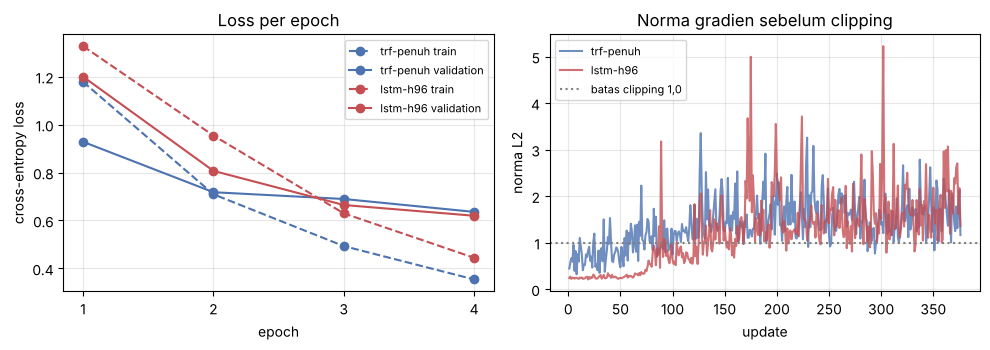

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
epoch = np.arange(1, EPOCHS + 1)
for nama, warna in zip(KONFIG_TERBIMBING, ['#4C72B0', '#C44E52']):
    hist = riwayat_terbimbing[nama]
    ax[0].plot(epoch, hist['train_loss'], marker='o', linestyle='--', color=warna, label=f'{nama} train')
    ax[0].plot(epoch, hist['val_loss'], marker='o', color=warna, label=f'{nama} validation')
    ax[1].plot(np.arange(1, len(hist['grad_norm']) + 1), hist['grad_norm'], color=warna,
               label=nama, alpha=0.8)
ax[0].set(title='Loss per epoch', xlabel='epoch', ylabel='cross-entropy loss', xticks=epoch)
ax[1].set(title='Norma gradien sebelum clipping', xlabel='update', ylabel='norma L2')
ax[1].axhline(1.0, color='gray', linestyle=':', label='batas clipping 1,0')
for a in ax:
    a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## G. Peta attention dan biaya panjang · Terbimbing

Peta memakai model `trf-penuh` terlatih dari bagian F. Contoh yang dipilih memiliki 12–30 token asli, tanpa sisa entitas HTML, dan dengan `<unk>` paling sedikit, sehingga seluruh peta $n\times n$ token asli terbaca.

contoh validasi #23, label 2, 25 token asli + 35 kolom bantalan
massa bobot ke bantalan: 0.00e+00 (harus nol)


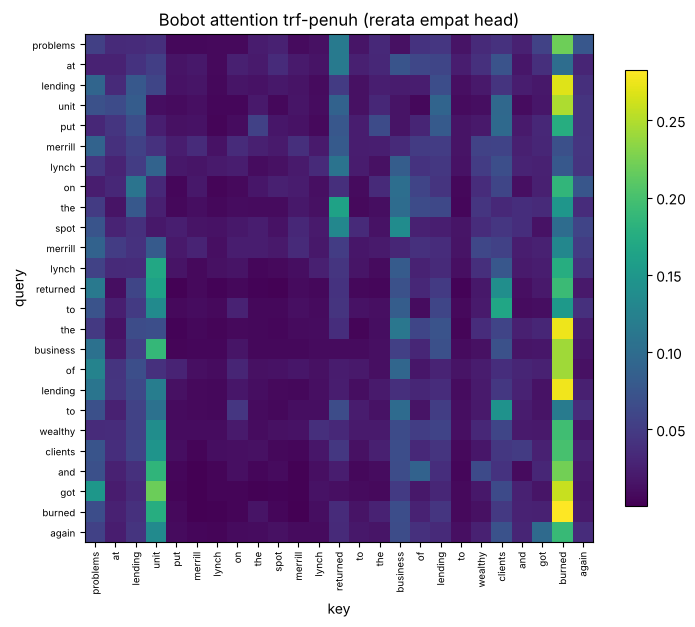

tiga pasangan query -> key berbobot tertinggi (posisi dalam kurung):
  burned (23) -> burned (23): 0.282
  lending (17) -> burned (23): 0.276
  the (14) -> burned (23): 0.275


In [16]:
# Peta attention trf-penuh terlatih: need_weights=True, dengan mask bantalan.
model = simpan['trf-penuh'].to('cpu').eval()
# Contoh 12-30 token asli agar seluruh peta n x n terbaca; utamakan contoh tanpa sisa
# entitas HTML (&lt; &gt; &quot; &#39; &amp;) dan dengan <unk> paling sedikit.
ARTEFAK = {stoi[t] for t in ('lt', 'gt', 'quot', '39', 'amp') if t in stoi}
def urutan_contoh(j):
    t = X_val[j, :int(L_val[j])].tolist()
    return (bool(set(t) & ARTEFAK), t.count(1), j)
kandidat = [j for j in range(len(X_val)) if 12 <= int(L_val[j]) <= 30]
i = min(kandidat, key=urutan_contoh) if kandidat else int(L_val.argmax())
x, l = X_val[i:i + 1], int(L_val[i])
token = [itos[int(t)] for t in x[0, :l]]
with torch.no_grad():
    h = model.masukan(x)
    _, w = model.layer.self_attn(h, h, h, key_padding_mask=(x == 0),
                                 need_weights=True)

sisa = w[0, :l, l:].sum().item()
print(f'contoh validasi #{i}, label {y_val[i]}, {l} token asli + {x.size(1) - l} kolom bantalan')
print(f'massa bobot ke bantalan: {sisa:.2e} (harus nol)')
assert sisa < 1e-6
k = min(l, 30)
fig, ax = plt.subplots(figsize=(7.4, 6.4))
im = ax.imshow(w[0, :k, :k].numpy(), cmap='viridis')
ax.set_xticks(range(k)); ax.set_xticklabels(token[:k], rotation=90, fontsize=7)
ax.set_yticks(range(k)); ax.set_yticklabels(token[:k], fontsize=7)
ax.set_xlabel('key'); ax.set_ylabel('query')
ax.set_title('Bobot attention trf-penuh (rerata empat head)')
fig.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

datar = w[0, :l, :l].flatten()
pasangan = []                    # (query, key, bobot, posisi query, posisi key); pasangan token unik
for j in datar.argsort(descending=True).tolist():
    qi, ki = divmod(j, l)
    if (token[qi], token[ki]) not in [(p[0], p[1]) for p in pasangan]:
        pasangan.append((token[qi], token[ki], float(datar[j]), qi, ki))
    if len(pasangan) == 3:
        break
print('tiga pasangan query -> key berbobot tertinggi (posisi dalam kurung):')
for q, kk, bb, qi, ki in pasangan:
    print(f'  {q} ({qi}) -> {kk} ({ki}): {bb:.3f}')

**Dua pasangan token berbobot tertinggi.** Pasangan dan penilaiannya dibangun dari peta di atas. Kata fungsi (daftar stop word bahasa Inggris scikit-learn), sisa entitas HTML seperti `39` (dari `&#39;`) atau `quot`, dan token `<unk>` ditandai sebagai token tanpa isi topik; `ap`, `afp`, dan `reuters` ditandai sebagai tag kantor berita.

In [17]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

SUMBER = {'ap', 'afp', 'reuters'}                       # tag kantor berita, bukan bagian isi kalimat
TANPA_ISI = set(ENGLISH_STOP_WORDS) | {'<unk>', 's', "'s", '39', 'quot', 'lt', 'gt', 'amp', 'b', 'said'}

def jenis_pasangan(q, k, qi, ki):
    if qi == ki:
        return 'token memperhatikan dirinya sendiri; wajar pada satu layer, tetapi bukan relasi antarkata'
    if q == k:
        return (f'dua kemunculan token `{q}` yang sama saling memperhatikan; ini pencocokan identitas '
                'token, bukan relasi antarkata')
    if k in SUMBER:
        return (f'key `{k}` adalah tag kantor berita, bukan bagian isi kalimat; ini pola data AG News, '
                'bukan relasi linguistik')
    if k in TANPA_ISI:
        return f'key `{k}` tidak membawa isi topik; lebih mirip pola perhatian umum daripada relasi makna'
    if q in TANPA_ISI or q in SUMBER:
        return (f'query `{q}` tidak membawa isi topik, sedangkan key `{k}` kata isi; masuk akal sebagai '
                'aliran konteks ke token fungsi, bukan relasi antara dua kata bermakna')
    return (f'keduanya kata isi; masuk akal secara linguistik bila `{q}` dan `{k}` membentuk frasa '
            'atau menunjuk topik yang sama dalam kalimat ini')

display(Markdown('\n'.join(
    f'- `{q}` ({qi}) → `{k}` ({ki}), bobot {b:.3f}: {jenis_pasangan(q, k, qi, ki)}.'
    for q, k, b, qi, ki in pasangan[:2]
) + '\n\nBobot attention hanya menunjukkan ke mana informasi dialirkan pada satu layer ini, bukan '
    'penjelasan sebab-akibat prediksi. Pembuktian memerlukan ablasi, misalnya menghapus token lalu '
    'melihat perubahan logit.'))

- `burned` (23) → `burned` (23), bobot 0.282: token memperhatikan dirinya sendiri; wajar pada satu layer, tetapi bukan relasi antarkata.
- `lending` (17) → `burned` (23), bobot 0.276: keduanya kata isi; masuk akal secara linguistik bila `lending` dan `burned` membentuk frasa atau menunjuk topik yang sama dalam kalimat ini.

Bobot attention hanya menunjukkan ke mana informasi dialirkan pada satu layer ini, bukan penjelasan sebab-akibat prediksi. Pembuktian memerlukan ablasi, misalnya menghapus token lalu melihat perubahan logit.

In [18]:
# Waktu satu forward pass (batch 64, tanpa bantalan) untuk n in (30, 60, 120);
# satu pemanggilan pemanasan, lalu median 30 ulangan (tahan terhadap lonjakan beban CPU).
@torch.no_grad()
def waktu_forward(model, n, ulang=30, batch=64):
    model = model.to(DEVICE).eval()
    g = torch.Generator().manual_seed(BASE_SEED)
    x = torch.randint(2, V, (batch, n), generator=g).to(DEVICE)
    l = torch.full((batch,), n, dtype=torch.long)
    model(x, l); sync_device()                     # pemanasan
    waktu = []
    for _ in range(ulang):
        mulai = time.perf_counter()
        model(x, l); sync_device()
        waktu.append(time.perf_counter() - mulai)
    return 1000 * float(np.median(waktu))

baris = []
for n_ in (30, 60, 120):
    baris.append({'n': n_,
                  'lstm_ms': waktu_forward(simpan['lstm-h96'], n_),
                  'transformer_ms': waktu_forward(simpan['trf-penuh'], n_)})
biaya = pd.DataFrame(baris)
biaya['rasio_lstm'] = biaya['lstm_ms'] / biaya['lstm_ms'].iloc[0]
biaya['rasio_trf'] = biaya['transformer_ms'] / biaya['transformer_ms'].iloc[0]
print(biaya.to_string(index=False))

  n  lstm_ms  transformer_ms  rasio_lstm  rasio_trf
 30   2.8225          5.1301      1.0000     1.0000
 60   5.2427         13.1871      1.8575     2.5705
120  11.2429         65.9672      3.9834    12.8588


## Latihan Mandiri di Lab

Tanpa melatih ulang, bentuk model dengan $`h\in\{1,2,4,10\}`$ pada $`d_{\text{model}}=100`$ yang tetap. Laporkan jumlah parameter keempatnya dan jelaskan mengapa angkanya sama. Kemudian ukur waktu satu forward pass untuk setiap $`h`$ dan tuliskan satu alasan yang dapat diuji atas perbedaannya.

Tuliskan prediksi, hasil, dan perbandingannya di `latihan-09.md`, lalu kumpulkan lewat tugas **Latihan Mandiri di Lab — Modul 09**.

**Prediksi:** Jumlah parameter satu layer encoder akan **sama** untuk $h\in\{1,2,4,10\}$, yaitu 76.075 (multi-head 40.400 + feed-forward 35.275 + dua LayerNorm 400), karena $W_Q,W_K,W_V,W_O$ selalu berukuran $d_{\text{model}}\times d_{\text{model}}$ dan $h$ hanya membagi kolomnya menjadi $h$ potongan berukuran $d_k=d_{\text{model}}/h$.

Untuk waktu forward pass (batch 64, $n=60$), prediksi saya: waktu naik **sedikit** seiring $h$ (sekitar 0-15% dari $h=1$ ke $h=10$), dengan $h=10$ paling lambat. **Alasan yang dapat diuji:** total perkalian matriks $QK^\top$ sama untuk semua $h$ (FLOP $\propto n^2 d_{\text{model}}$), tetapi tensor bobot attention berukuran $B\times h\times n\times n$ dan jumlah entri softmax tumbuh $\propto h$. Jika alasan ini benar, selisih antara $h=10$ dan $h=1$ harus **lebih besar pada $n=120$** daripada pada $n=60$ (karena entri softmax $\propto h\,n^2$). Jika selisihnya di bawah rentang derau pengukuran, prediksi ini tidak terbukti.

In [19]:
# Bentuk model dengan n_head berbeda pada D_MODEL=100 tetap, tanpa melatih ulang.
baris = []
for h in (1, 2, 4, 10):
    seed_everything(BASE_SEED)
    m = TransformerClassifier(nhead=h).eval()
    p_attn = sum(p.numel() for p in m.layer.self_attn.parameters())
    p_layer = sum(p.numel() for p in m.layer.parameters())
    assert p_layer == parameter_layer(D_MODEL, FF), 'rumus harus cocok dengan PyTorch'
    # Waktu forward: median 30 ulangan (waktu_forward), diulang 5 kali untuk menaksir derau.
    ms60 = [waktu_forward(m, 60) for _ in range(5)]
    ms120 = [waktu_forward(m, 120) for _ in range(5)]
    baris.append({'n_head': h, 'd_k': D_MODEL // h, 'parameter_attn': p_attn,
                  'parameter_layer': p_layer,
                  'ms_n60': float(np.median(ms60)), 'rentang_n60': max(ms60) - min(ms60),
                  'ms_n120': float(np.median(ms120)), 'rentang_n120': max(ms120) - min(ms120)})
tabel_head = pd.DataFrame(baris)
print(tabel_head.to_string(index=False))
assert tabel_head['parameter_layer'].nunique() == 1, 'parameter layer harus sama untuk semua h'
assert tabel_head['parameter_attn'].nunique() == 1
t = tabel_head.set_index('n_head')
print(f"rasio waktu h=10 / h=1: n=60 -> {t.loc[10, 'ms_n60'] / t.loc[1, 'ms_n60']:.3f} | "
      f"n=120 -> {t.loc[10, 'ms_n120'] / t.loc[1, 'ms_n120']:.3f}")

 n_head  d_k  parameter_attn  parameter_layer  ms_n60  rentang_n60  ms_n120  rentang_n120
      1  100           40400            76075 10.3455       3.2377  21.3254        1.3889
      2   50           40400            76075 11.0602       1.3621  30.3682        2.6139
      4   25           40400            76075 13.3343       0.7266  64.2896       10.8723
     10   10           40400            76075 25.2547       2.3794 111.0421        4.9842
rasio waktu h=10 / h=1: n=60 -> 2.441 | n=120 -> 5.207


### Hasil dan perbandingan dengan prediksi

**Jawaban:**

| $h$ | $d_k$ | Parameter multi-head | Parameter layer | ms ($n=60$, rentang) | ms ($n=120$, rentang) |
|---:|---:|---:|---:|---:|---:|
| 1 | 100 | 40.400 | 76.075 | 10,35 (3,24) | 21,33 (1,39) |
| 2 | 50 | 40.400 | 76.075 | 11,06 (1,36) | 30,37 (2,61) |
| 4 | 25 | 40.400 | 76.075 | 13,33 (0,73) | 64,29 (10,87) |
| 10 | 10 | 40.400 | 76.075 | 25,25 (2,38) | 111,04 (4,98) |

**Mengapa parameternya sama.** $W_Q,W_K,W_V,W_O$ selalu berukuran $d_{\text{model}}\times d_{\text{model}}$, sehingga multi-head memiliki $4d^2+4d=40.400$ parameter untuk setiap $h$; $h$ tidak muncul pada rumus. Head hanya membagi kolom proyeksi menjadi $h$ potongan berukuran $d_k=d_{\text{model}}/h$.

**Terhadap prediksi.**
- *Parameter:* prediksi 76.075 per layer untuk semua $h$ **terbukti** (dan cocok dengan PyTorch lewat `assert`).
- *Arah waktu:* naik seiring $h$, sesuai prediksi.
- *Besar waktu:* **meleset jauh.** Prediksi kenaikan 0-15%, hasilnya $h=10$ adalah 2,44 kali $h=1$ pada $n=60$ (+144%). Selisih $h=1$ dan $h=2$ (0,71 ms) masih di dalam rentang derau (3,24 ms), tetapi selisih $h=1$ dan $h=10$ (14,9 ms) jauh di atasnya.
- *Alasan yang diuji:* selisih pada $n=120$ memang lebih besar (rasio 5,21) daripada pada $n=60$ (2,44), konsisten dengan entri softmax $\propto h\,n^2$. Namun uji ini tidak memisahkan mekanismenya: ukuran $d_k$ yang kecil (10) membuat perkalian matriks per head kurang efisien di CPU, dan itu juga dapat menjelaskan kenaikan tersebut.

## H. Dua belas run multi-seed - 25 poin · Tugas Individu

In [20]:
# Dua belas run (empat konfigurasi x tiga seed) dengan protokol penuh (MODE_TUGAS=True).
# `buat_loader`, `evaluasi`, `bangun`, dan `jalankan` sudah tersedia dari bagian F.

KONFIG = ['lstm-h96', 'trf-tanpa-posisi', 'trf-tanpa-mask', 'trf-penuh']
hasil, riwayat, simpan = [], {}, {}
for seed in SEEDS:
    for nama in KONFIG:
        print(f'Melatih {nama}, seed={seed} ...')
        mdl, hist, row = jalankan(nama, seed)
        hasil.append(row); riwayat[(nama, seed)] = hist; simpan[nama] = mdl

tabel = pd.DataFrame(hasil)
print(tabel[['run_id', 'encoder_head_parameters', 'total_parameters',
             'val_loss', 'val_accuracy', 'grad_norm_mean',
             'seconds_per_epoch']].to_string(index=False))
assert len(tabel) == len(KONFIG) * len(SEEDS)
assert tabel.groupby('seed')['n_updates'].nunique().max() == 1, \
    'seluruh konfigurasi harus memakai anggaran update yang sama'
if MODE_TUGAS:
    assert len(tabel) == 12, 'hasil pengumpulan wajib memuat dua belas run'

Melatih lstm-h96, seed=121 ...


  epoch 1/4  train_loss 1.3271  val_loss 1.1999  val_acc 0.4680


  epoch 2/4  train_loss 0.9542  val_loss 0.8069  val_acc 0.6853


  epoch 3/4  train_loss 0.6296  val_loss 0.6644  val_acc 0.7507


  epoch 4/4  train_loss 0.4442  val_loss 0.6196  val_acc 0.7707


Melatih trf-tanpa-posisi, seed=121 ...


... (51 outputs left out)

  epoch 2/4  train_loss 0.7207  val_loss 0.6849  val_acc 0.7360


  epoch 3/4  train_loss 0.5333  val_loss 0.6357  val_acc 0.7760


  epoch 4/4  train_loss 0.4024  val_loss 0.6137  val_acc 0.7893


               run_id  encoder_head_parameters  total_parameters  val_loss  val_accuracy  grad_norm_mean  seconds_per_epoch
        lstm-h96-s121                    76420           1262620    0.6196        0.7707          1.2246             6.5151
trf-tanpa-posisi-s121                    76479           1262679    0.6377        0.7953          0.7056             6.9195
  trf-tanpa-mask-s121                    76479           1262679    0.6418        0.7860          1.5444             6.5220
       trf-penuh-s121                    76479           1262679    0.6357        0.7973          1.4018             6.8152
        lstm-h96-s122                    76420           1262620    0.6789        0.7813          1.2830             6.6249
trf-tanpa-posisi-s122                    76479           1262679    0.6290        0.7873          0.7027             7.4326
  trf-tanpa-mask-s122                    76479           1262679    0.6329        0.7867          1.5069             7.0889
       t

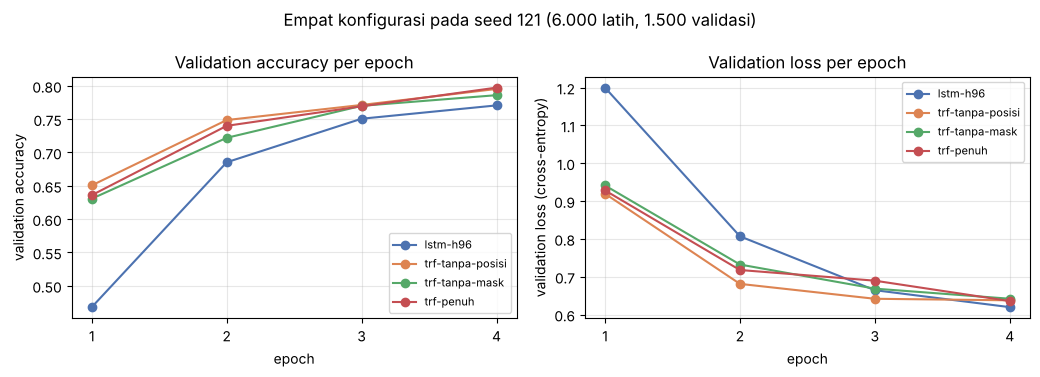

In [21]:
# Dua panel: validation accuracy dan validation loss per epoch pada BASE_SEED.
WARNA = {'lstm-h96': '#4C72B0', 'trf-tanpa-posisi': '#DD8452', 'trf-tanpa-mask': '#55A868', 'trf-penuh': '#C44E52'}
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
epoch = np.arange(1, EPOCHS + 1)
for nama in KONFIG:
    hist = riwayat[(nama, BASE_SEED)]
    ax[0].plot(epoch, hist['val_acc'], marker='o', color=WARNA[nama], label=nama)
    ax[1].plot(epoch, hist['val_loss'], marker='o', color=WARNA[nama], label=nama)
ax[0].set(title='Validation accuracy per epoch', xlabel='epoch', ylabel='validation accuracy', xticks=epoch)
ax[1].set(title='Validation loss per epoch', xlabel='epoch', ylabel='validation loss (cross-entropy)', xticks=epoch)
fig.suptitle(f'Empat konfigurasi pada seed {BASE_SEED} (6.000 latih, 1.500 validasi)')
for a in ax:
    a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'M09_{NIM}_fig1.png', dpi=150); plt.show()

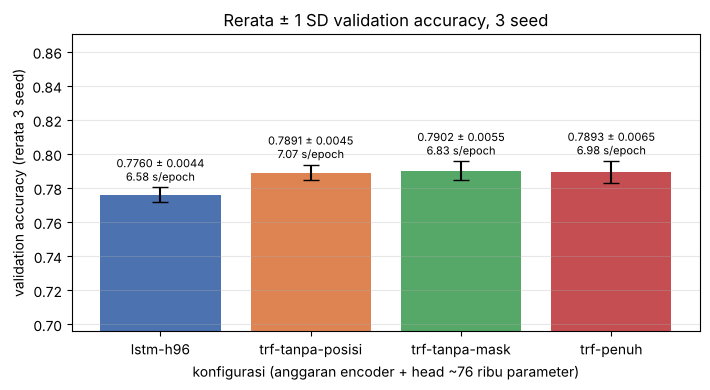

     konfigurasi  acc_mean  acc_std  seconds_mean  encoder_head_parameters  total_parameters  model_mib
        lstm-h96    0.7760   0.0044        6.5797                    76420           1262620     4.8165
trf-tanpa-posisi    0.7891   0.0045        7.0663                    76479           1262679     4.8167
  trf-tanpa-mask    0.7902   0.0055        6.8313                    76479           1262679     4.8167
       trf-penuh    0.7893   0.0065        6.9754                    76479           1262679     4.8167


In [22]:
# Ringkasan tiga seed per konfigurasi (SD populasi, ddof=0).

tabel['konfigurasi'] = tabel['run_id'].str.rsplit('-s', n=1).str[0]
ringkasan = (tabel.groupby('konfigurasi', sort=False)
             .agg(acc_mean=('val_accuracy', 'mean'),
                  acc_std=('val_accuracy', lambda s: s.std(ddof=0)),
                  seconds_mean=('seconds_per_epoch', 'mean'),
                  encoder_head_parameters=('encoder_head_parameters', 'first'),
                  total_parameters=('total_parameters', 'first'),
                  model_mib=('model_mib_fp32', 'first'))
             .reset_index())

fig, ax = plt.subplots(figsize=(7.2, 4.0))
batang = ax.bar(ringkasan['konfigurasi'], ringkasan['acc_mean'], yerr=ringkasan['acc_std'], capsize=6,
                color=[WARNA[k] for k in ringkasan['konfigurasi']])
for b, (_, r) in zip(batang, ringkasan.iterrows()):
    ax.annotate(f"{r.acc_mean:.4f} ± {r.acc_std:.4f}\n{r.seconds_mean:.2f} s/epoch",
                (b.get_x() + b.get_width() / 2, r.acc_mean + r.acc_std),
                ha='center', va='bottom', fontsize=8, xytext=(0, 3), textcoords='offset points')
ax.set(xlabel='konfigurasi (anggaran encoder + head ~76 ribu parameter)',
       ylabel='validation accuracy (rerata 3 seed)', title='Rerata ± 1 SD validation accuracy, 3 seed',
       ylim=(max(0, ringkasan['acc_mean'].min() - 0.08), min(1.0, ringkasan['acc_mean'].max() + 0.08)))
ax.grid(alpha=.3, axis='y'); plt.tight_layout()
plt.savefig(f'M09_{NIM}_fig2.png', dpi=150); plt.show()
print(ringkasan.to_string(index=False))
assert len(ringkasan) == 4

In [23]:
# Simpan seluruh run ke metrics.csv.
if MODE_TUGAS:
    tabel.insert(1, 'student_id', NIM)
    output = Path(f'M09_{NIM}_metrics.csv')
    tabel.to_csv(output, index=False)
    print(f'{len(tabel)} baris disimpan ke {output}')
else:
    print('MODE_TUGAS masih False; metrics.csv belum ditulis.')

12 baris disimpan ke M09_123450121_metrics.csv


## I. Pertanyaan analisis dan keputusan - 10 poin · Tugas Individu

1. **Selisih Transformer penuh terhadap LSTM.** Transformer penuh 0,7893 ± 0,0065 vs LSTM 0,7760 ± 0,0044: selisih **+1,33 poin persentase**. Per seed: +2,67, 0,00 (keduanya 0,7813), dan +1,33 poin. Selisih rerata melebihi SD masing-masing model (0,65 dan 0,44 poin) tetapi hanya sekitar dua kali lipatnya, dan satu dari tiga seed imbang. Dengan tiga seed, keunggulan Transformer belum dapat dipastikan lebih besar daripada variasi antar-seed.
2. **Penurunan akibat mematikan penyandian posisi.** Hampir nol: 0,7891 tanpa posisi vs 0,7893 dengan posisi (-0,02 poin; per seed +0,20, -0,60, +0,47). Probe permutasi pada model belum terlatih menunjukkan model tanpa posisi benar-benar tidak peka urutan (selisih logit 3,0e-08, dengan posisi 0,0046), jadi kemampuannya hilang. Namun AG News dapat diklasifikasi dari kata-kata penanda topik dengan rata-rata (mirip rerata embedding pada Modul 7), sehingga hilangnya urutan tidak merugikan akurasi pada tugas ini. Probe menunjukkan *kemampuan* arsitektur, bukan *kebutuhan* tugas.
3. **Penurunan akibat mematikan mask.** Tidak ada penurunan: 0,7902 tanpa mask vs 0,7893 dengan mask (+0,09 poin; per seed -1,13, +0,53, +0,87 poin untuk selisih tanpa-mask minus penuh, yaitu campuran). Kesalahan ini tidak menimbulkan galat karena bentuk tensor tetap valid dan softmax tetap berjalan; `<pad>` hanya diperlakukan sebagai token tambahan, dan pooling hanya dibagi 60, bukan panjang asli. Pada protokol ini jumlah bantalan konsisten antara latih dan validasi sehingga model menyesuaikan diri. Bahayanya terlihat pada probe: menambah 20 kolom bantalan mengubah logit 0,1684 tanpa mask (0,0 dengan mask), dan 12,03 total massa bobot (rata-rata 0,201 per query dari 20 kolom) jatuh pada bantalan. Jadi hasilnya bergantung pada panjang bantalan di sebuah batch, yang berbahaya saat inferensi dengan batch berbeda.
4. **Kecepatan pada n=60 dan n=120; O(n) vs O(n^2).** LSTM lebih cepat pada keduanya: 5,24 vs 13,19 ms pada $n=60$ (2,5 kali) dan 11,24 vs 65,97 ms pada $n=120$ (5,9 kali). Dari $n=30$ ke $n=120$ (4 kali lebih panjang), waktu LSTM naik 3,98 kali (mendekati linear, 4) dan Transformer naik 12,86 kali (mendekati kuadratik, 16). Dari $n=60$ ke 120 Transformer naik 5,0 kali, lebih dari 4 kali yang diharapkan kuadratik murni; penyebabnya (misalnya cache atau overhead CPU) tidak saya uji. Pengukuran memakai satu CPU dan model hasil seed 121.
5. **Pilihan untuk teks jauh lebih panjang dengan memori tetap: LSTM.** Tiga angka: (a) waktu pada $n=120$ 11,24 ms (LSTM) vs 65,97 ms (Transformer), dan skala dari $n=30$ ke 120 sebesar 3,98 vs 12,86 kali; (b) memori bobot attention tumbuh $\propto h\,n^2$ (hitungan, bukan pengukuran): $4\times1000^2\times4$ byte = 16 MB per contoh per layer pada $n=1000$, sedangkan keadaan LSTM tetap $2\times96\times4=768$ byte; (c) ukuran parameter hampir sama (76.420 vs 76.479 parameter; 4,8165 vs 4,8167 MiB), jadi ukuran model tidak membedakan. Keunggulan akurasi Transformer (+1,33 poin) hanya diukur pada $n=60$ dan tidak pasti. Catatan: implementasi attention hemat memori dapat mengurangi biaya memori ini, dan model ini tidak diuji pada $n>120$.

## Checklist sebelum mengumpulkan

- [x] Identitas terisi dan `MODE_TUGAS=True`.
- [x] Attention buatan sendiri cocok dengan PyTorch di bawah $10^{-5}$.
- [x] Empat angka entropi dilaporkan terhadap $\log 64$.
- [x] Ketiga probe dijalankan pada model belum terlatih dan berupa angka.
- [x] Selisih anggaran encoder + head terhadap LSTM tidak lebih dari 1%.
- [x] Dua belas run tercatat, termasuk kedua ablasi yang benar-benar dilatih.
- [x] Norma gradien dicatat sebelum clipping.
- [x] Peta attention memperlihatkan kolom bantalan bernilai nol.
- [x] Waktu forward pass diukur untuk $n \in \{30, 60, 120\}$.
- [x] Test set tidak dipakai untuk tuning atau pemilihan model.
- [x] `metrics.csv` memuat seluruh run.
- [x] Notebook lolos *Restart Kernel and Run All*.